## TASK 1:

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
saurus_df = pd.read_csv("data/datasaurus.csv")
print(saurus_df.shape)

(1846, 3)


In [8]:
summary_table = (saurus_df.groupby("dataset").agg(std_x=("x", "std"),
                std_y=("y", "std"),avg_x=("x", "mean"),
                avg_y=("y", "mean"),correlation=("x", lambda x_col: x_col.corr(saurus_df.loc[x_col.index, "y"])))
                .round(2))
summary_table

,std_x,std_y,avg_x,avg_y,correlation
dataset,,,,,
away,16.77,26.94,54.27,47.83,-0.06
bullseye,16.77,26.94,54.27,47.83,-0.07
circle,16.76,26.93,54.27,47.84,-0.07
dino,16.77,26.94,54.26,47.83,-0.06
dots,16.77,26.93,54.26,47.84,-0.06
h_lines,16.77,26.94,54.26,47.83,-0.06
high_lines,16.77,26.94,54.27,47.84,-0.07
slant_down,16.77,26.94,54.27,47.84,-0.07
slant_up,16.77,26.94,54.27,47.83,-0.07


 All 13 rows look almost the same:
- mean of x is about 54.27
- mean of y is about 47.83
- std of x is about 16.77
- std of y is about 26.93
- correlation is about -0.06 to -0.07

If the table was all I had, I would say the 13 datasets are basically the same data. I would also say x and y have almost no relationship, because the correlation is close to 0.

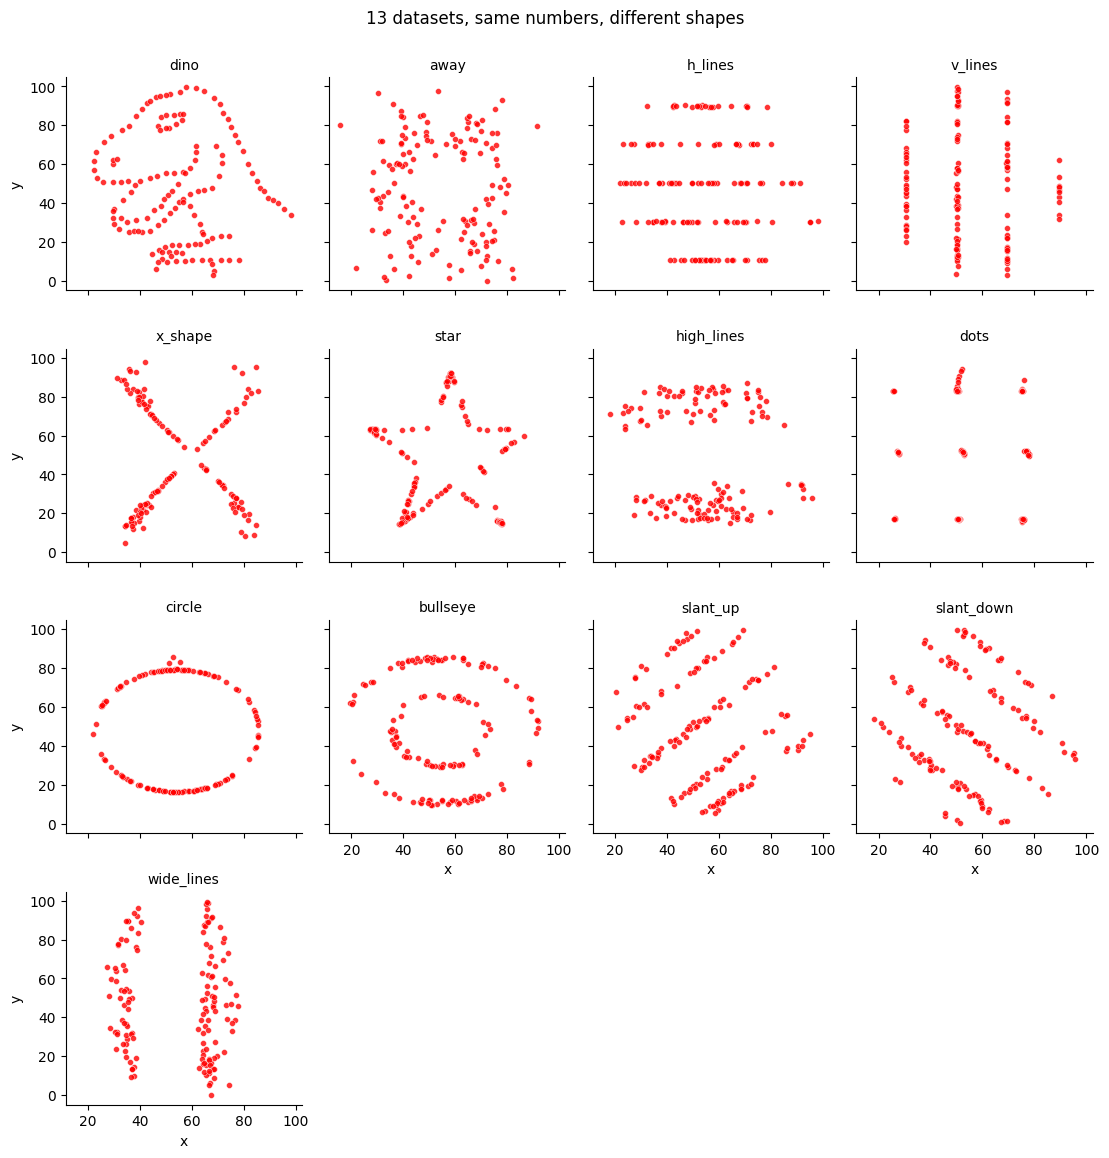

In [11]:
grid = sns.FacetGrid(saurus_df, col="dataset", col_wrap=4, height=2.8)
grid.map(sns.scatterplot, "x", "y", s=18, color="red", alpha=0.8)
grid.set_titles(col_template="{col_name}")
grid.figure.suptitle("13 datasets, same numbers, different shapes", y=1.03)
plt.show()

The plots look completely different from each other. One is a dinosaur. Others are a star, a circle, a bullseye, an X shape, and different kinds of lines. So what I thought from the table (they are all the same) was **wrong**.

The correlation close to 0 does not mean "no relationship". Many of these have a clear pattern. Correlation only measures straight-line relationships, so shapes like a circle or a star give a number close to 0.

## Question: 
- More points make the mean and std less noisy (142 points is better than 11). But that only fixes noise.
- Here the problem is not noise. Mean, std and correlation turn all the points into a few numbers, so the **shape is lost**. Very different shapes can give the same numbers.
- These datasets were made on purpose to give the same numbers, so more points cannot fix it.
- Anscombe had 11 points and Datasaurus has 142 points, but the lesson is the same. 13 datasets just gives me 13 examples of the same warning.

So the summary stats can be correct and still be misleading. 

## TASK 2: 

In [13]:
gap = pd.read_csv("data/gapminder.csv")
print(gap.shape)  

(1704, 6)


The file has 1,704 rows: 142 countries x 12 years (1952 to 2007, every 5 years).
The columns are `country`, `continent`, `year`, `lifeExp`, `pop`, `gdpPercap`.

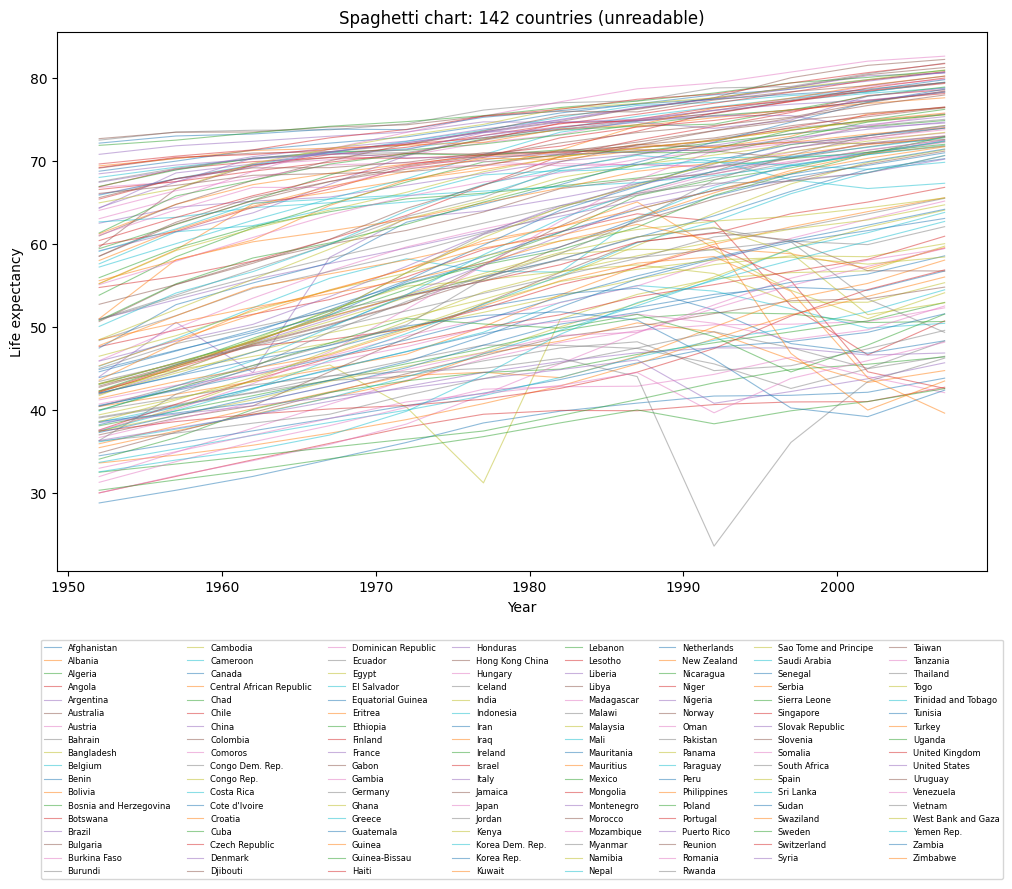

In [23]:
plt.figure(figsize=(12, 7))
for c, g in gap.groupby("country"):
    plt.plot(g["year"], g["lifeExp"], alpha=0.5, linewidth=0.8, label=c)   # label=c so the legend has names
plt.title("Spaghetti chart: 142 countries (unreadable)")
plt.xlabel("Year")
plt.ylabel("Life expectancy")
plt.legend(ncol=8, fontsize=6, loc="upper center", bbox_to_anchor=(0.5, -0.12))   # legend below the chart
plt.show()

**What is wrong with this chart:**
- Too many lines on top of each other
- The legend has 142 names, so it is useless
- Colours repeat, so I can't tell which line is which
- No clear message
- Big drops (like Rwanda) are hidden in the pile

a)aggregate

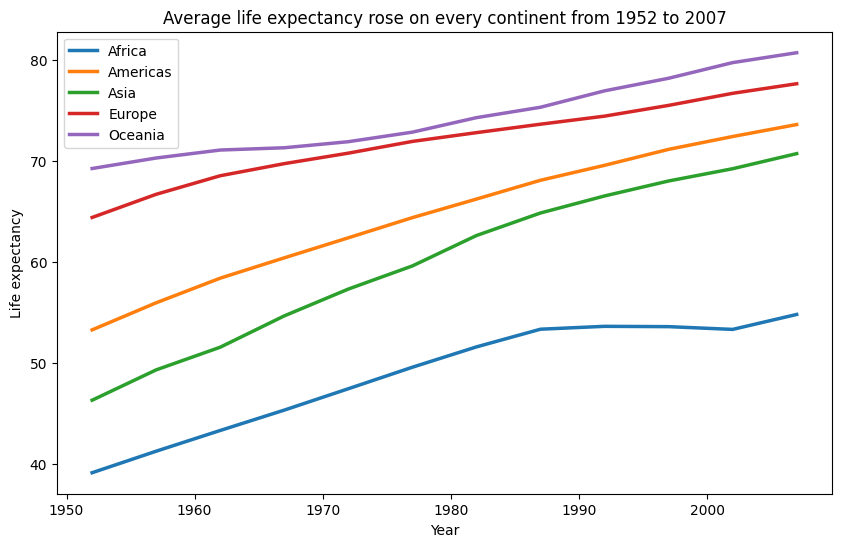

In [17]:
con = gap.groupby(["continent", "year"])["lifeExp"].mean().reset_index()

plt.figure(figsize=(10, 6))
for n, g in con.groupby("continent"):      
    plt.plot(g["year"], g["lifeExp"], label=n, linewidth=2.5)
plt.legend()
plt.title("Average life expectancy rose on every continent from 1952 to 2007")
plt.xlabel("Year")
plt.ylabel("Life expectancy")
plt.show()

b) Highlight

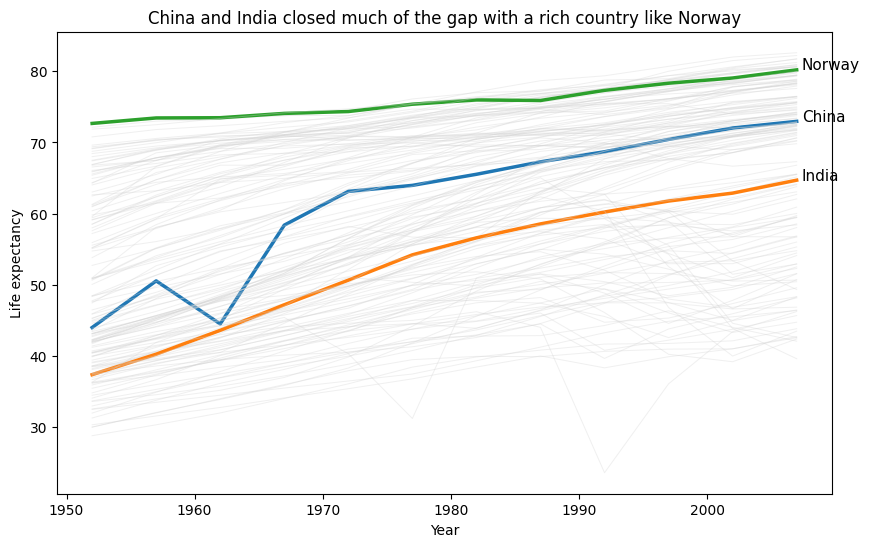

In [18]:
pick = ["China", "India", "Norway"]         

plt.figure(figsize=(10, 6))
for c, g in gap.groupby("country"):
    if c in pick:
        plt.plot(g["year"], g["lifeExp"], linewidth=2.5)
        end = g.iloc[-1]                     # last row = year 2007
        plt.text(end["year"] + 0.4, end["lifeExp"], c, fontsize=11)   # name written on the line
    else:
        plt.plot(g["year"], g["lifeExp"], color="lightgrey", alpha=0.35, linewidth=0.7)

plt.title("China and India closed much of the gap with a rich country like Norway")
plt.xlabel("Year")
plt.ylabel("Life expectancy")
plt.show()

I picked China and India because they started very low and went up a lot. I picked Norway as a rich country to compare with. The grey lines show all the other countries.

## 3. Compare (a) and (b)
**(a) Continent lines**
- Can show: the big picture for each continent
- Cannot show: single countries (the Africa line hides Rwanda's drop)

**(b) Highlighted countries**
- Can show: single country stories compared with all the others
- Cannot show: a clear comparison between continents

(a) is good for the overall trend. (b) is good for single stories.

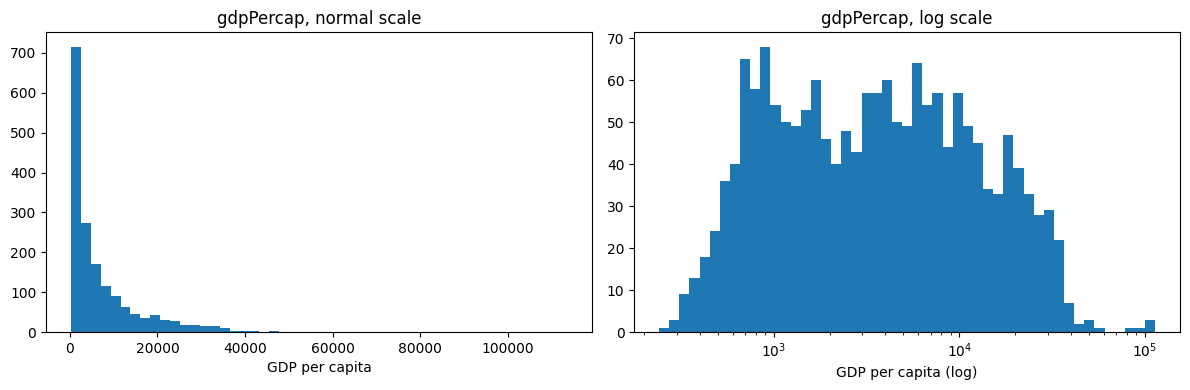

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].hist(gap["gdpPercap"], bins=50)        # normal scale: squashed on the left
ax[0].set_title("gdpPercap, normal scale")
ax[0].set_xlabel("GDP per capita")

# log scale: bins must be spaced on a log scale too
bins = np.logspace(np.log10(gap["gdpPercap"].min()), np.log10(gap["gdpPercap"].max()), 50)
ax[1].hist(gap["gdpPercap"], bins=bins)
ax[1].set_xscale("log")
ax[1].set_title("gdpPercap, log scale")
ax[1].set_xlabel("GDP per capita (log)")

plt.tight_layout()
plt.show()

On the normal scale, most countries are squashed on the left and a few very rich ones make a long tail. The log scale spreads them out.

**Decision: use a log scale.** On a log scale the same distance means the same ratio ("10 times richer"), so it fits a question about the gap.

          p90    p10  ratio
year                       
1952   7255.3  495.0   14.7
1957   9667.9  576.0   16.8
1962  10967.2  603.1   18.2
1967  14060.6  701.6   20.0
1972  16606.2  724.1   22.9
1977  19091.7  741.5   25.7
1982  19467.7  789.7   24.7
1987  21866.5  738.0   29.6
1992  24752.2  737.3   33.6
1997  26905.6  789.3   34.1
2002  29980.1  767.4   39.1
2007  33644.1  887.3   37.9


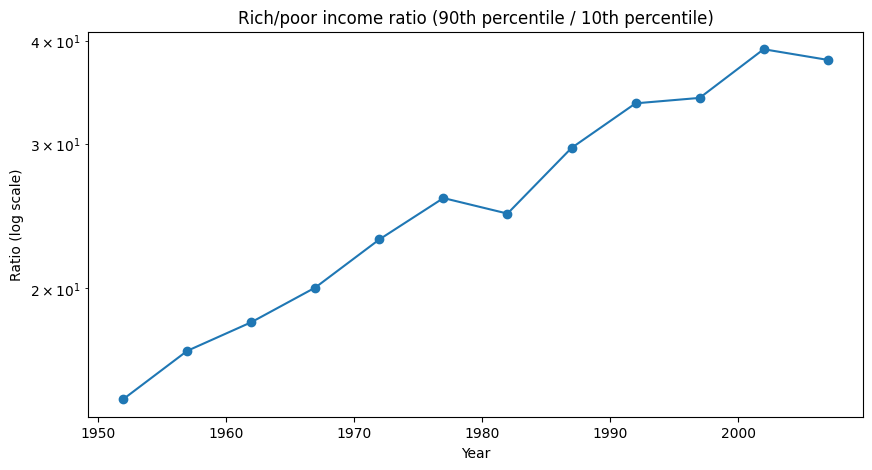

In [22]:
rp = (gap.groupby("year")
         .agg(p90=("gdpPercap", lambda s: s.quantile(0.9)),
              p10=("gdpPercap", lambda s: s.quantile(0.1)))
         .assign(ratio=lambda t: t["p90"] / t["p10"]))   # how many times richer
print(rp.round(1))                                        # look at the numbers too

plt.figure(figsize=(10, 5))
plt.plot(rp.index, rp["ratio"], marker="o")
plt.yscale("log")
plt.title("Rich/poor income ratio (90th percentile / 10th percentile)")
plt.ylabel("Ratio (log scale)")
plt.xlabel("Year")
plt.show()

**My chart:** a line chart of the ratio of the 90th percentile (rich) to the 10th percentile (poor), with a log y-axis.
- Percentiles, not min and max, because min and max are just one country each
- Line chart, because the x-axis is time

**Answer: No, the gap got wider.** The rich were about 15 times richer in 1952 and about 38 times richer in 2007.

## TASK 3:


In [24]:
raw = pd.read_csv("data/penguins.csv")
print(raw.isna().sum())   

species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64


In [25]:
cols = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]

print("no measurements:", raw[cols].isna().all(axis=1).sum())
print("no sex:", raw["sex"].isna().sum())

no measurements: 2
no sex: 11


**Missing values:**
- 2 penguins have no measurements, so I removed them (342 left).
- 11 penguins have no sex. I keep them for charts that don't use sex. I only remove them for the sex chart.

In [26]:
pen = raw.dropna(subset=cols)
print(pen.shape)

note = "n = 342 (2 penguins with no measurements removed)"

(342, 7)


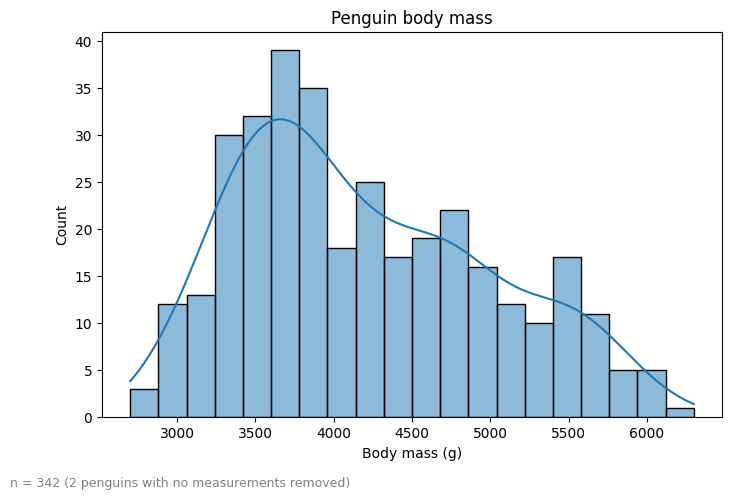

In [28]:
plt.figure(figsize=(8, 5))
sns.histplot(pen["body_mass_g"], bins=20, kde=True)
plt.title("Penguin body mass")
plt.xlabel("Body mass (g)")
plt.figtext(0.01, -0.03, note, fontsize=9, color="grey")
plt.show()

It is not one clean hump. The biggest hump is at about 3,500 to 3,800 g, and there are more bumps further right.
So it looks like more than one group mixed together.

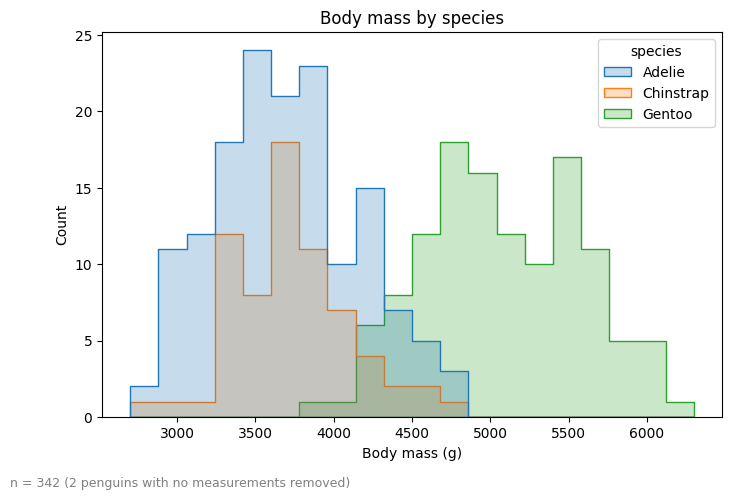

In [30]:
# By Species
plt.figure(figsize=(8, 5))
sns.histplot(data=pen, x="body_mass_g", hue="species", element="step", bins=20)
plt.title("Body mass by species")
plt.xlabel("Body mass (g)")
plt.figtext(0.01, -0.03, note, fontsize=9, color="grey")
plt.show()

Yes, this explains most of it. Adelie and Chinstrap are small and sit in the same place. Gentoo is much heavier and makes the second hump. The first chart was different groups mixed together.

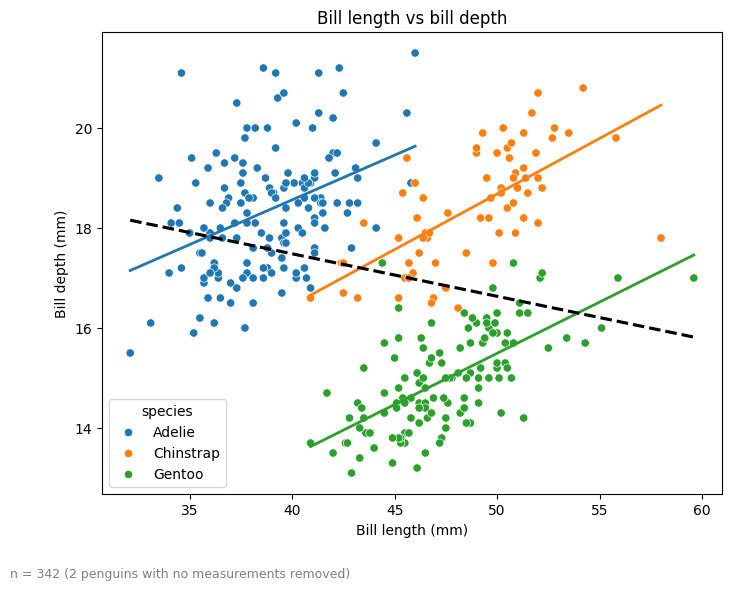

all together: -0.24
Adelie 0.39
Chinstrap 0.65
Gentoo 0.64


In [32]:
# Bill length vs bill depth
plt.figure(figsize=(8, 6))
sns.scatterplot(data=pen, x="bill_length_mm", y="bill_depth_mm", hue="species")

for sp, g in pen.groupby("species"):
    sns.regplot(data=g, x="bill_length_mm", y="bill_depth_mm",
                scatter=False, ci=None, line_kws={"linewidth": 2})

sns.regplot(data=pen, x="bill_length_mm", y="bill_depth_mm",
            scatter=False, ci=None, color="black", line_kws={"linestyle": "--"})

plt.title("Bill length vs bill depth")
plt.xlabel("Bill length (mm)")
plt.ylabel("Bill depth (mm)")
plt.figtext(0.01, -0.03, note, fontsize=9, color="grey")
plt.show()

print("all together:", pen["bill_length_mm"].corr(pen["bill_depth_mm"]).round(2))
for sp, g in pen.groupby("species"):
    print(sp, g["bill_length_mm"].corr(g["bill_depth_mm"]).round(2))

- All penguins together: the dashed line goes **down** (correlation -0.24).
- Inside each species: the lines go **up** (0.39, 0.65, 0.64).

The species sit in different places. Gentoo has long but shallow bills. Adelie has short but deep bills. So the hidden thing, **species**, flips the overall trend.

This is **Simpson's paradox**. Always plot the groups separately.

(333, 7)


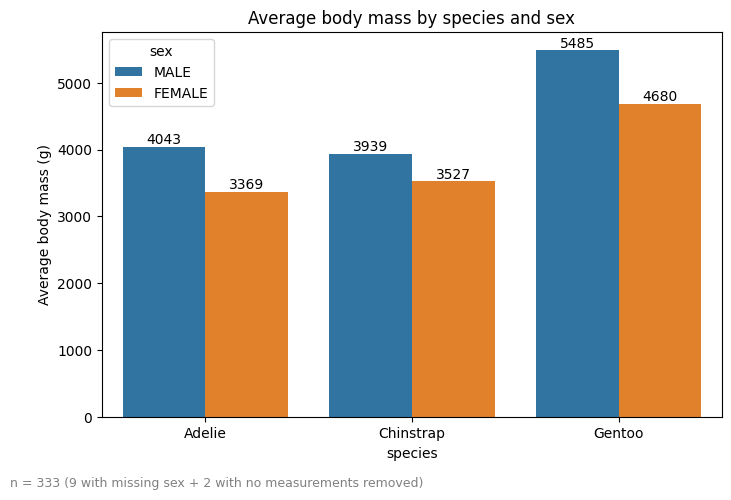

In [33]:
# Species and sex
pen_s = pen.dropna(subset=["sex"])
print(pen_s.shape)

plt.figure(figsize=(8, 5))
ax = sns.barplot(data=pen_s, x="species", y="body_mass_g", hue="sex", errorbar=None)
for b in ax.containers:
    ax.bar_label(b, fmt="%.0f")
plt.title("Average body mass by species and sex")
plt.ylabel("Average body mass (g)")
plt.figtext(0.01, -0.03, "n = 333 (9 with missing sex + 2 with no measurements removed)",
            fontsize=9, color="grey")
plt.show()

Males are heavier than females in every species. Gentoo is the heaviest. A Gentoo female is even heavier than the males of the other two species.